## Practice Activity 8-2: Intro to Machine Learning; Linear Regression Models — INSTRUCTOR SOLUTION

**How to use this notebook.** Each part is answered in the same five beats: **Approach** (the idea, in a sentence
or two) → **code** (complete and executed) → **What the code does** → **Expected output** → **Common mistakes**
(what students actually do, and the symptom on their screen).

**Scope.** Students know regression from other courses; the point here is the scikit-learn recipe from Topic 8.2
(`X` as a DataFrame → `fit` → `coef_` → `predict`) applied to three model shapes (linear, log outcome, quadratic),
to a categorical predictor (dummify it), and to an interaction (a column you multiply yourself). The last question
of each half ("which model is best?") is where the machine-learning idea lands: judge on data the model did not
fit — a train/test split or cross-validation — not on the fitted $R^2$.

Model names used throughout: `linear_model`, `log_model`, `square_model` (the student notebook already refers to
`square_model` in part 5), then `smoke_model`, `smoke_age_model`, `interaction_model`.

In [1]:
import pandas as pd

import numpy as np

## Music Challenge

Which popular songs from the past will be recognized by future generations, and which will fade into obscurity? The website [The Pudding](https://pudding.cool/) conducts the [Music Challenge](https://pudding.cool/2020/04/music-challenge/) where they ask thousands of people whether they recognize hit songs from the past. We'll look at some of the [data](https://github.com/the-pudding/song-decay-clean/tree/master/src/assets/data) related to the article ["Defining the 90s Music Canon"](https://pudding.cool/2020/07/song-decay/).

The data set at https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv contains 344 songs released in the 1990s. For each song, the proportion of survey respondents who recognized the song is recorded, for both Millennial respondents and Gen Z respondents. Our goal will be to use linear regression to **predict the Gen Z recognition**.

We will try several different linear regression models. Save each of your models with a different name because you will compare them at the end.



0. Read in the data and describe the Gen Z recognition variable.

### Solution 0 — read the data and describe Gen Z recognition

**Approach.** `read_csv` from the URL, rename the two long column names, then `.describe()` the outcome. Also
import what the rest of the notebook needs.

In [2]:
from plotnine import ggplot, aes, geom_point, geom_line, labs, theme_minimal
from sklearn.linear_model import LinearRegression

songs = pd.read_csv("https://raw.githubusercontent.com/the-pudding/song-decay-clean/refs/heads/master/src/assets/data/lollipop_chart_data_july_13.csv")
songs = songs.rename(columns={"mean_millennial_recognition": "millennial", "mean_gen_z_recognition": "gen_z"})
print(songs.shape)
songs.head()

(344, 3)


,artist_song,millennial,gen_z
0,2 Pac|||California Love,0.517602,0.268378
1,2Pac|||How Do U Want It,0.209632,0.062439
2,702|||Where My Girls At?,0.553481,0.244176
3,Ace Of Base|||All That She Wants,0.830967,0.540097
4,Ace Of Base|||Don't Turn Around,0.623149,0.372787


In [3]:
songs["gen_z"].describe().round(3)

count    344.000
mean       0.236
std        0.211
min        0.019
25%        0.096
50%        0.155
75%        0.303
max        0.963
Name: gen_z, dtype: float64

**What the code does.** One row per song (344): the song, the share of Millennial respondents who recognised
it, and the share of Gen Z respondents who did. `describe()` gives the five-number summary of the outcome.

**Expected output.** `(344, 3)`. Gen Z recognition: mean 0.236, median 0.155, min 0.019, max 0.963. The
mean is well above the median and the top quarter stretches from 0.30 to 0.96 — the distribution is
**right-skewed**: most 90s hits are recognised by fewer than one Gen Z respondent in five, and a handful
(*...Baby One More Time*, *My Heart Will Go On*, *Wannabe*, *All Star*) by almost everyone. Worth noticing
now: the variable is a **proportion**, so it lives between 0 and 1.

**Common mistakes.**
- Leaving the column names as `mean_gen_z_recognition` — fine, just verbose; the renaming is a convenience.
- `songs.describe()` without selecting the column also describes Millennial recognition; not wrong, but the
  question asks about Gen Z.

1. Use scikit-learn to fit a linear regression model for predicting Gen Z recognition from Millennial recognition.

### Solution 1 — linear model: Gen Z ~ Millennial

**Approach.** The Topic 8.2 recipe. `X` is a one-column DataFrame (double brackets), `y` a Series.

In [4]:
X = songs[["millennial"]]
y = songs["gen_z"]

linear_model = LinearRegression().fit(X, y)
print("intercept:", round(linear_model.intercept_, 4))
print("slope:    ", linear_model.coef_.round(4))
print("R²:       ", round(linear_model.score(X, y), 3))

intercept: -0.0481
slope:     [0.7067]
R²:        0.797


**What the code does.** `fit` finds the least-squares line; `intercept_` and `coef_` are the fitted numbers
(`coef_` is an array, one entry per feature); `score` is $R^2$ on the fitted data.

**Expected output.** gen_z ≈ −0.048 + 0.707 · millennial, $R^2$ ≈ 0.80. A song recognised by 10 percentage
points more Millennials is recognised by about 7 points more Gen Z respondents. The **negative intercept**
is the first hint that a straight line is the wrong shape: a song that no Millennial recognises is predicted
to have *negative* Gen Z recognition. Eleven songs in the data already get a negative prediction.

**Common mistakes.**
- `songs["millennial"]` (single brackets) → `ValueError: Expected a 2-dimensional container`. Double brackets.
- Reading `coef_` as a number: it is `array([0.7067])`; index it with `[0]` if you want the scalar.

2. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

### Solution 2 — scatterplot with the fitted line

**Approach.** The reliable way to overlay *any* fitted model (this works unchanged for the log and quadratic
models later): build a grid of x-values, `predict` on the grid, and draw it with `geom_line` on top of
`geom_point`. (`geom_smooth(method="lm")` would also draw this particular line, but not the next two.)

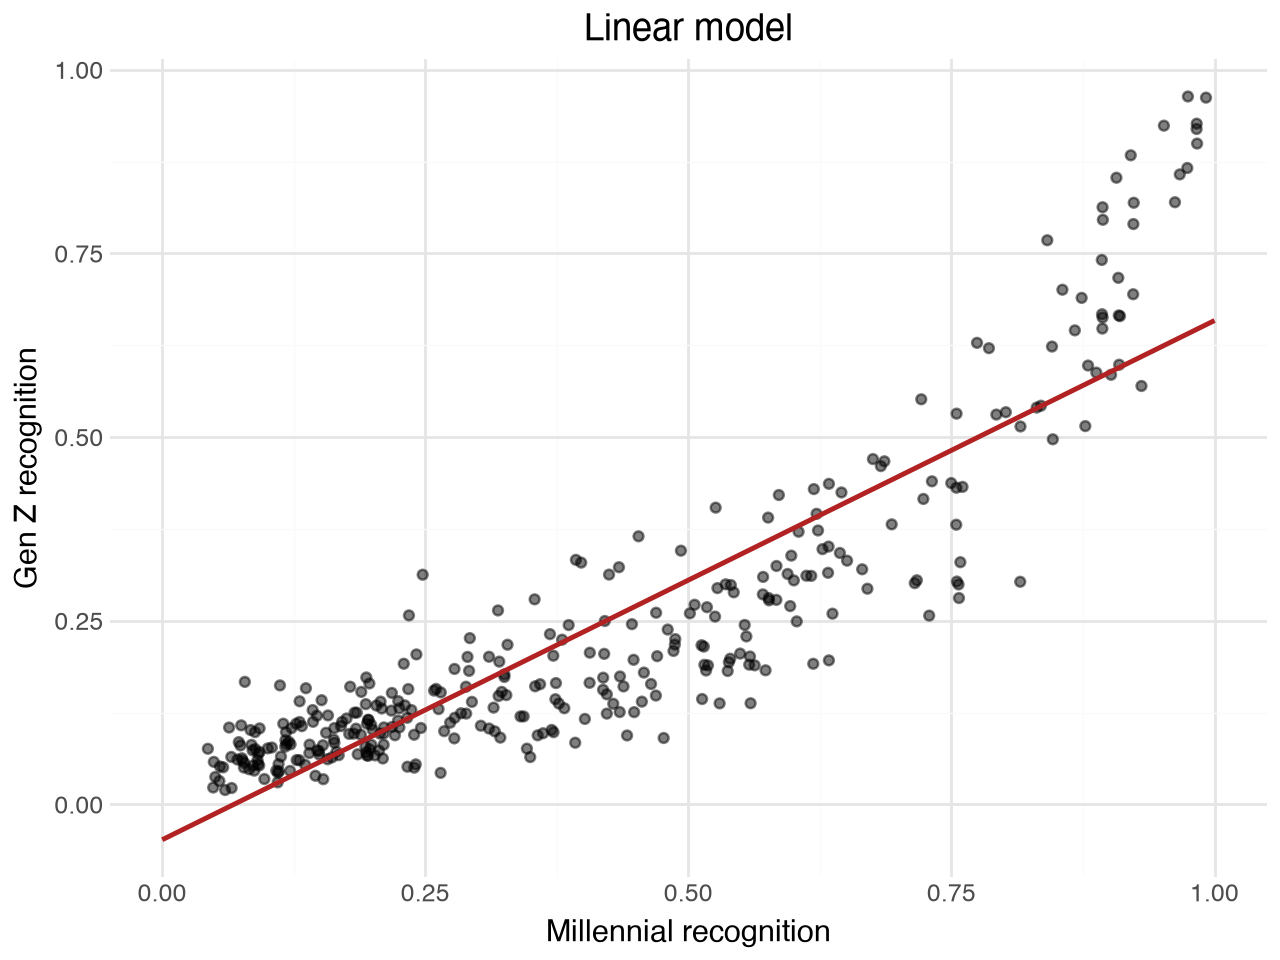

In [5]:
grid = pd.DataFrame({"millennial": np.linspace(0, 1, 101)})
grid["linear"] = linear_model.predict(grid[["millennial"]])

(ggplot(songs, aes(x="millennial", y="gen_z"))
 + geom_point(alpha=0.5)
 + geom_line(grid, aes(x="millennial", y="linear"), color="firebrick", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Linear model")
 + theme_minimal())

**What the code does.** `np.linspace(0, 1, 101)` is 101 evenly spaced budgets of "millennial" from 0 to 1;
`predict` needs a DataFrame with the same column name as `X`, so the grid is built as one. `geom_line` takes
its own `data=` and `aes`, so the line is drawn from `grid` while the points come from `songs`.

**Expected output.** A cloud that is clearly **curved**: flat near zero for the bottom half of the Millennial
range, then rising steeply. The straight line sits *above* the points at the low end (it dips below zero at
the far left) and *below* them at the top right — classic underfitting of a curve.

**Common mistakes.**
- `geom_line(aes(y=linear_model.predict(X)))` on the unsorted `songs` — works by accident for a line but
  produces a scribble for the curves in parts 4 and 6; the grid approach is the one to learn.
- Forgetting `[["millennial"]]` on the grid → the same 2-D error as part 1.

3. Explain why you might want to consider taking a log of Gen Z recognition. Then use scikit-learn to fit a linear regression model for predicting log of Gen Z recognition from Millennial recognition.

### Solution 3 — why a log, and the log model

**Why take the log of Gen Z recognition.** Three reasons, any one of which earns the mark:
1. The outcome is a **proportion bounded at 0** and right-skewed; a straight line in the raw scale predicts
   negative values for the least-known songs (part 1). `log(gen_z)` has no floor, so a line in log scale can
   never predict below zero once you exponentiate back.
2. The scatter in part 2 **curves upward**: Gen Z recognition grows *multiplicatively* with Millennial
   recognition (each extra bit of Millennial fame multiplies, rather than adds to, Gen Z fame). A log on the
   outcome turns a multiplicative relationship into an additive one — a straight line.
3. The spread of points is **wider at the top** than at the bottom; logging the outcome evens it out.

**Approach.** Same recipe; the only change is `y = np.log(songs["gen_z"])`. No song has recognition 0, so the
log is defined everywhere.

In [6]:
y_log = np.log(songs["gen_z"])

log_model = LinearRegression().fit(X, y_log)
print("intercept:", round(log_model.intercept_, 4))
print("slope:    ", log_model.coef_.round(4))
print("R² (log scale):", round(log_model.score(X, y_log), 3))

intercept: -2.9083
slope:     [2.7992]
R² (log scale): 0.823


**What the code does.** `np.log` is vectorised, so one call logs every song. The model is linear in
`log(gen_z)`: log(gen_z) ≈ −2.91 + 2.80 · millennial. To get a prediction in the original units, exponentiate:
gen_z ≈ e^(−2.91 + 2.80 · millennial). Each extra 0.1 of Millennial recognition **multiplies** predicted
Gen Z recognition by e^0.28 ≈ 1.32.

**Expected output.** intercept −2.908, slope 2.799, $R^2$ 0.823 — but note that this $R^2$ is on the **log
scale** and is *not* comparable with part 1's 0.80. Part 7 compares the models properly, in the original
units.

**Common mistakes.**
- `np.log(songs["gen_z"] + 1)` — unnecessary here (no zeros) and it changes the model; `log1p` is for counts
  with zeros.
- Forgetting to exponentiate when predicting (parts 4, 7, 8): `log_model.predict(...)` returns a *log*
  recognition, e.g. −0.95, which students then report as the prediction.
- Comparing the log-scale $R^2$ (0.823) directly with the linear model's (0.797) and concluding "a bit better".

4. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model from the previous part.

### Solution 4 — scatterplot with the log model's curve

**Approach.** Same grid; predict on the log scale and `np.exp` it back before plotting, so the curve is in the
units of the points.

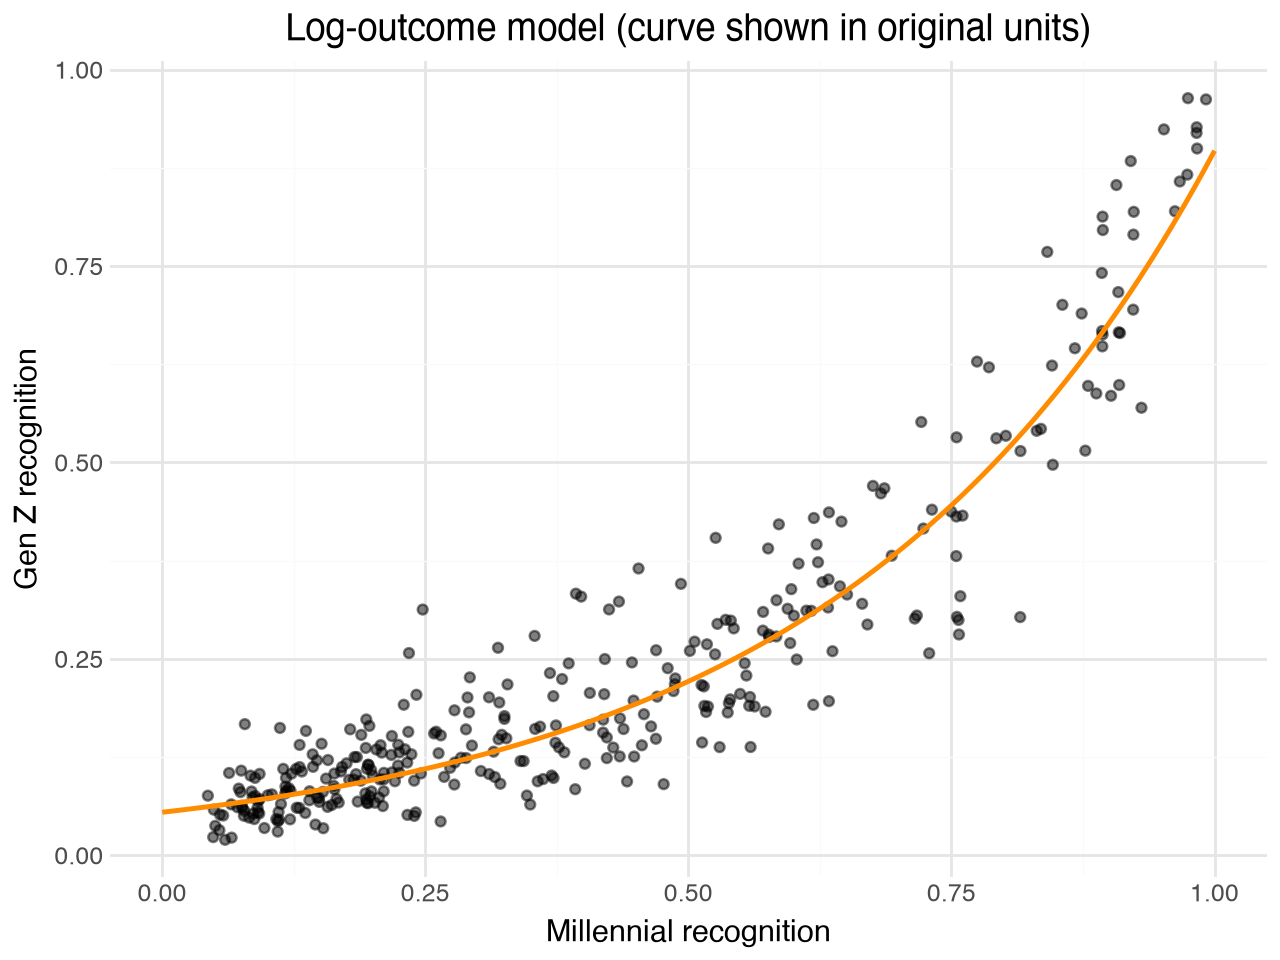

In [7]:
grid["log"] = np.exp(log_model.predict(grid[["millennial"]]))

(ggplot(songs, aes(x="millennial", y="gen_z"))
 + geom_point(alpha=0.5)
 + geom_line(grid, aes(x="millennial", y="log"), color="darkorange", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Log-outcome model (curve shown in original units)")
 + theme_minimal())

**What the code does.** `np.exp(...)` undoes the log so that the fitted values are back on the 0–1 scale.

**Expected output.** An exponential curve: ≈ 0.05 at the left edge (never negative), rising to ≈ 0.9 at
Millennial = 1. It follows the bottom-left of the cloud far better than the line did, and bends up through
the top-right cluster.

**Common mistakes.**
- Plotting `log_model.predict(grid)` without `np.exp` → a straight line from −2.9 to −0.1 on a plot whose
  points sit between 0 and 1.
- Plotting `np.log(gen_z)` on the y-axis instead — a valid plot, but the question asks for Gen Z recognition
  versus Millennial recognition.

5. Now we'll try a polynomial model for predicting Gen Z recognition from Millennial recognition. Use scikit-learn to fit a model with two features: Millennial recognition and its square.

### Solution 5 — quadratic model: Millennial and its square

**Approach.** A polynomial term is **just another column** (Topic 8.2, section 3): square the feature, put both
columns in `X`, fit. The notebook's next cell reads `square_model.coef_`, so the model must carry that name.

In [8]:
songs["millennial_sq"] = songs["millennial"] ** 2
X_sq = songs[["millennial", "millennial_sq"]]

square_model = LinearRegression().fit(X_sq, y)
print("R²:", round(square_model.score(X_sq, y), 3))

R²: 0.898


**What the code does.** `** 2` squares every value; `X_sq` has two columns, so `coef_` has two entries, in
column order. (`PolynomialFeatures(degree=2)` would build the same two columns; by hand is clearer here.)

**Expected output.** The next cell prints `(array([-0.2726, 1.0207]), 0.1085)`: gen_z ≈ 0.109 − 0.273 ·
millennial + 1.021 · millennial². $R^2$ ≈ 0.898 on the original scale — the best of the three so far on the
fitted data. The negative linear term with a positive square gives a curve that is flat (even slightly
decreasing) at the low end and accelerates upward.

**Common mistakes.**
- Fitting on `millennial_sq` **alone** (one column) — the question says two features.
- Naming the model something else, so the pre-written `square_model.coef_` cell fails with `NameError`.
- Squaring the *outcome* instead of the feature.

In [9]:
square_model.coef_, square_model.intercept_

(array([-0.27263527,  1.02072241]), np.float64(0.10851294576257645))

6. Make a scatterplot of Gen Z recognition versus Millennial recognition, and overlay a graph of the fitted model.

### Solution 6 — scatterplot with the quadratic curve

**Approach.** The grid needs the squared column too, with the **same name** as in `X_sq`.

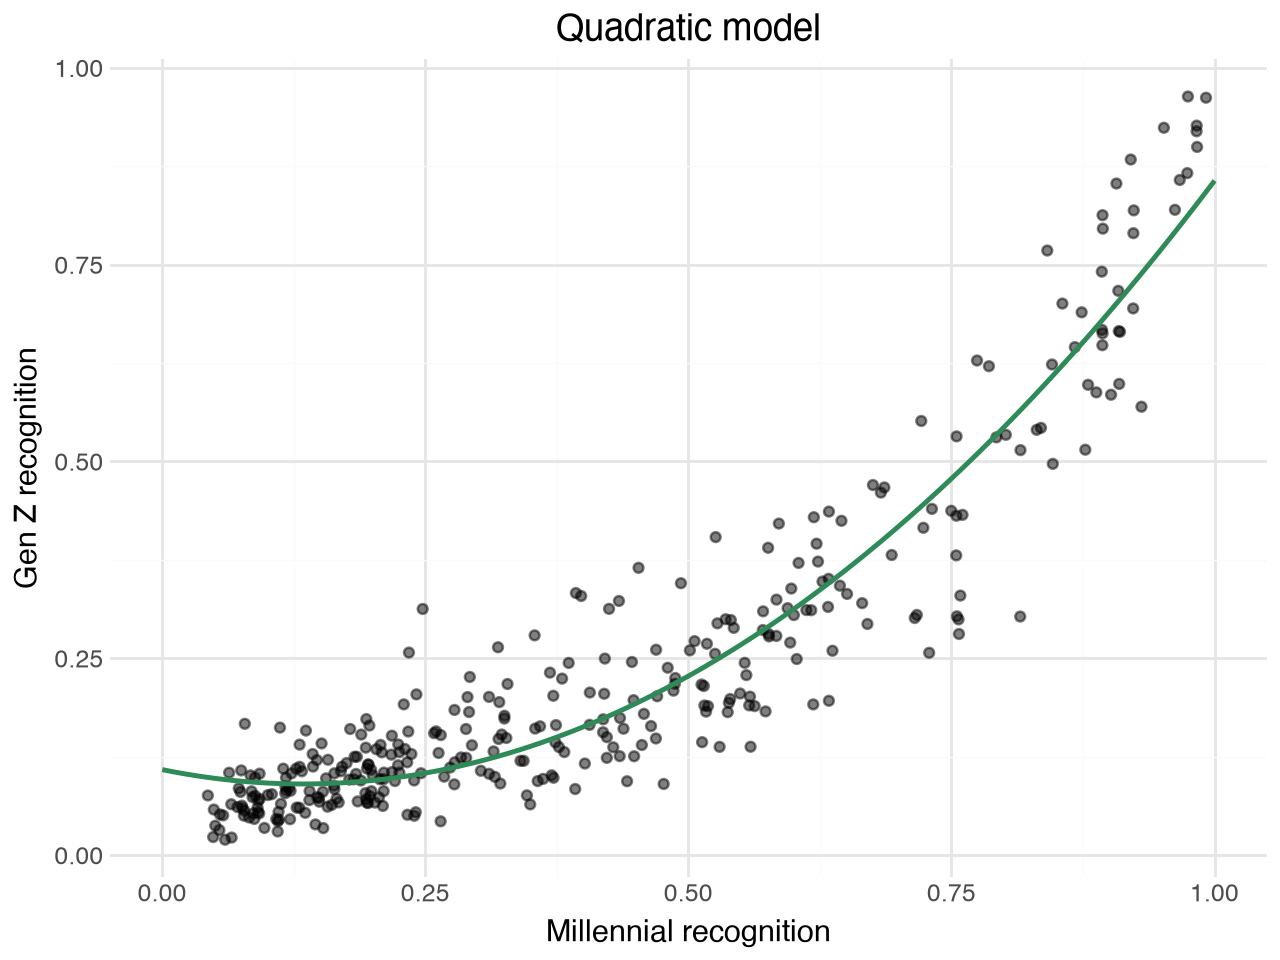

In [10]:
grid["millennial_sq"] = grid["millennial"] ** 2
grid["square"] = square_model.predict(grid[["millennial", "millennial_sq"]])

(ggplot(songs, aes(x="millennial", y="gen_z"))
 + geom_point(alpha=0.5)
 + geom_line(grid, aes(x="millennial", y="square"), color="seagreen", size=1)
 + labs(x="Millennial recognition", y="Gen Z recognition", title="Quadratic model")
 + theme_minimal())

**What the code does.** `predict` is given the two columns in the order the model was fitted on.

**Expected output.** A parabola that hugs the cloud: ≈ 0.11 at the left, a shallow dip to ≈ 0.09 around
Millennial = 0.13, then a steep rise to ≈ 0.86 at the right. Visually hard to distinguish from the log curve
except at the very left, where the quadratic is flat and the log curve keeps falling toward 0.

**Common mistakes.**
- `square_model.predict(grid[["millennial"]])` → `ValueError: X has 1 features, but LinearRegression is
  expecting 2 features`. The prediction table must have every column the model was fitted on.
- Columns in the wrong order or with a different name (`millennial^2`) → a wrong curve or a feature-name
  warning.

7. Choose one of your favorite songs that is in the data set. Use each model to predict the Gen Z recognition for the song. Which model gives the best prediction?

### Solution 7 — predict one song with each model

**Approach.** Pick a song that is in the data (here *Waterfalls* by TLC; any row works), build a one-row
prediction table with every feature any model needs, and call `predict` on each model — remembering to
`np.exp` the log model. Then compare with the song's actual Gen Z recognition.

In [11]:
song = songs[songs["artist_song"].str.contains("Waterfalls")]
song

,artist_song,millennial,gen_z,millennial_sq
301,TLC|||Waterfalls,0.846265,0.496892,0.716165


In [12]:
def predict_all(millennial):
    new = pd.DataFrame({"millennial": [millennial], "millennial_sq": [millennial ** 2]})
    return pd.Series({
        "linear": linear_model.predict(new[["millennial"]])[0],
        "log":    np.exp(log_model.predict(new[["millennial"]]))[0],
        "square": square_model.predict(new[["millennial", "millennial_sq"]])[0],
    })

m = song["millennial"].iloc[0]
preds = predict_all(m)
print(f"actual Gen Z recognition: {song['gen_z'].iloc[0]:.3f}")
(preds.to_frame("predicted").assign(error=lambda d: d["predicted"] - song["gen_z"].iloc[0])).round(3)

actual Gen Z recognition: 0.497


,predicted,error
linear,0.550,0.053
log,0.583,0.086
square,0.609,0.112


**What the code does.** `predict_all` wraps the three predictions so parts 7 and 8 share one piece of code;
`[0]` pulls the single number out of the one-element array. The `error` column is predicted − actual.

**Expected output.** *Waterfalls*: Millennial 0.846, actual Gen Z 0.497. Predictions: linear ≈ 0.550, log
≈ 0.583, quadratic ≈ 0.609 — all three **over**-predict this song, the linear model by the least. So for this
one song the linear model "wins", which is a useful lesson: **one song cannot rank the models.** A single
prediction error mixes the model's systematic shape with that song's own luck. Part 9's question — judge on
many held-out songs — is the right way; see the extra cell below.

**Common mistakes.**
- Forgetting `np.exp` on the log model → "predicted recognition −0.54".
- Predicting with `songs.loc[i]` as a Series instead of a one-row DataFrame → the 2-D error.
- Choosing a song that is not in the 344 (e.g. *Smells Like Teen Spirit*) — that is part 8.

**Instructor extra — the honest comparison.** Which model predicts best *on average*, in the original units?
The right machine-learning move is to judge on songs the model did not fit. A quick 5-fold cross-validation
of the three models, scored by RMSE in the original 0–1 scale (so the log model is exponentiated before
scoring):

In [13]:
from sklearn.model_selection import KFold

def cv_rmse(make_X, transform_y=None, inverse=None, k=5):
    errors = []
    for train_idx, test_idx in KFold(k, shuffle=True, random_state=5544).split(songs):
        train, test = songs.iloc[train_idx], songs.iloc[test_idx]
        y_train = transform_y(train["gen_z"]) if transform_y else train["gen_z"]
        model = LinearRegression().fit(make_X(train), y_train)
        pred = model.predict(make_X(test))
        if inverse:
            pred = inverse(pred)
        errors.append(np.sqrt(((test["gen_z"] - pred) ** 2).mean()))
    return np.mean(errors)

pd.Series({
    "linear": cv_rmse(lambda d: d[["millennial"]]),
    "log":    cv_rmse(lambda d: d[["millennial"]], transform_y=np.log, inverse=np.exp),
    "square": cv_rmse(lambda d: d[["millennial", "millennial_sq"]]),
}).round(4)

linear    0.0951
log       0.0642
square    0.0674
dtype: float64

Cross-validated RMSE: linear ≈ 0.095, log ≈ 0.064, quadratic ≈ 0.067. The two curved models are a clear step
up from the line; between them the log model edges ahead, and it has the extra merit of never predicting a
negative recognition. (On the fitted data the quadratic's $R^2$ was slightly higher — 0.898 vs 0.907 for the
log model once its predictions are put back in original units — which is exactly the kind of small, fitted-data
difference cross-validation is there to check.)

8. The song "Smells Like Teen Spirit" by Nirvana is inexplicably not included in the data set. Suppose the Millenial recognition of this song is 0.7. Use each model to predict the Gen Z recognition for this song. Which model gives the best prediction?

### Solution 8 — *Smells Like Teen Spirit*, Millennial recognition 0.7

**Approach.** Same helper, new input. This time there is **no actual value to compare against** — the song is
not in the data — so "best" cannot be judged by error on this song at all.

In [14]:
predict_all(0.7).round(3)

linear    0.447
log       0.387
square    0.418
dtype: float64

**Expected output.** linear ≈ 0.447, log ≈ 0.387, quadratic ≈ 0.418 — a spread of about six percentage points
depending on the model.

**Which is best?** Without the true Gen Z recognition for *Smells Like Teen Spirit* there is no way to score
these three numbers. The only defensible answer is to trust the model that predicts best **on songs like it
that we do have** — the cross-validation above says the log model (closely followed by the quadratic), so
≈ 0.39 is the best available guess, with the honest caveat that songs at Millennial ≈ 0.7 in the data have
Gen Z recognition anywhere from ≈ 0.25 to ≈ 0.55. (Students who answer "the linear model, because it gives
the highest number" or "whichever is closest to my intuition" are confusing a prediction with a preference.)

**Common mistakes.**
- Reporting the log model's raw output (−0.95) as a recognition share.
- Claiming one model is "best" from this single prediction with no truth to compare against.

## Categorical Predictors (FEV data)

Do non-smokers have better lungs than smokers? One measure of lung function is forced expiratory volume (FEV), the amount of air (in liters) an individual can exhale in the first second of forceful breath.  Larger values of FEV are indicative of better functioning lungs. In a study, FEV was measured for a group of 654 subjects, along with whether or not they smoked and other variables.

In [15]:
df_fev = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/FEV.csv")

df_fev

,ID,Smoking status,FEV,Height,Age (months)
0,201,non-smoker,2.884,69.0,132
1,202,non-smoker,2.328,64.0,120
2,301,non-smoker,1.708,57.0,108
3,341,non-smoker,3.381,63.0,172
4,351,non-smoker,2.170,58.0,130
...,...,...,...,...,...
649,83841,non-smoker,2.115,50.0,58
650,83901,non-smoker,2.328,60.0,98
651,83951,smoker,3.069,65.0,130
652,83952,non-smoker,1.495,57.0,85


1\. First fit a regression model with a single predictor: Smoking status. Since this variable is categorical you need to "dummify" it before fitting the model.

### Solution FEV-1 — one categorical predictor: smoking status

**Approach.** scikit-learn needs numbers. "Dummify" the two-level variable into one 0/1 column (1 = smoker).
`pd.get_dummies(..., drop_first=True, dtype=int)` does it; so does a boolean comparison cast to `int`. Shorter
column names are also set here so later plot code is readable (`Age (months)` contains spaces and parentheses,
which plotnine's `aes` cannot parse as a column name).

In [16]:
df_fev = df_fev.rename(columns={"Smoking status": "smoking", "Age (months)": "age_months"})
df_fev["smoker"] = (df_fev["smoking"] == "smoker").astype(int)      # the dummy: 1 = smoker, 0 = non-smoker
print(df_fev["smoking"].value_counts())

smoke_model = LinearRegression().fit(df_fev[["smoker"]], df_fev["FEV"])
print("intercept:", round(smoke_model.intercept_, 4), " smoker coef:", smoke_model.coef_.round(4))
print("R²:", round(smoke_model.score(df_fev[["smoker"]], df_fev["FEV"]), 3))

smoking
non-smoker    589
smoker         65
Name: count, dtype: int64
intercept: 2.5661  smoker coef: [0.7107]
R²: 0.06


**What the code does.** The comparison gives `True`/`False`; `astype(int)` makes it 1/0. The model is
FEV ≈ 2.566 + 0.711 · smoker.

**Expected output.** 589 non-smokers, 65 smokers. Intercept 2.566, smoker coefficient **+0.711**, $R^2$ 0.06.

**Common mistakes.**
- `LinearRegression().fit(df_fev[["Smoking status"]], ...)` with the text column →
  `ValueError: could not convert string to float: 'non-smoker'`.
- `pd.get_dummies(df_fev["Smoking status"])` **without** `drop_first` → two perfectly collinear columns
  (`non-smoker` + `smoker` = 1). scikit-learn still fits, but the two coefficients are no longer
  interpretable on their own; one dummy per two-level variable.
- `get_dummies` returning `bool` columns in recent pandas — fine for `fit`, but pass `dtype=int` to be safe.

2\. What are the predictions from this model? How could we have known that those would be the predictions?

### Solution FEV-2 — the model's predictions, and why we could have guessed them

**Approach.** The only inputs are 0 and 1, so there are only two possible predictions. Compare them with the
group means.

In [17]:
two_groups = pd.DataFrame({"smoker": [0, 1]})
two_groups["predicted_FEV"] = smoke_model.predict(two_groups[["smoker"]])
print(two_groups)

df_fev.groupby("smoking")["FEV"].mean().round(4)

   smoker  predicted_FEV
0       0       2.566143
1       1       3.276862


smoking
non-smoker    2.5661
smoker        3.2769
Name: FEV, dtype: float64

**What the code does.** Predicts for the two possible values of the dummy, then computes the mean FEV of each
group directly.

**Expected output.** Non-smokers 2.566, smokers 3.277 — and the `groupby` means are **identical**. With a
single 0/1 predictor, least squares has one number to choose for each group, and the number that minimises
squared error within a group is that group's **mean**. So the intercept is the non-smoker mean and the
coefficient is the **difference in means** (3.277 − 2.566 = 0.711). We could have written both down from a
`groupby` without fitting anything.

**Common mistakes.**
- `smoke_model.predict(df_fev[["smoker"]])` on all 654 rows — correct but prints 654 copies of two numbers;
  `np.unique` or the two-row table is the point.

3\. Look at the results for the previous parts. What do you notice? Is this what you expected? Remember: larger FEV means better lungs - who tends to have larger FEV, smokers or non-smokers?

**Answer (FEV-3).** The model says smokers have **higher** FEV than non-smokers — 3.28 L against 2.57 L, a gap
of 0.71 L — and $R^2$ is only 0.06, so smoking status explains almost none of the variation anyway. That is
the opposite of what we expect: larger FEV means better lungs, so smokers *appear* to have the better lungs.
Not expected, and it should make us suspicious of the comparison rather than of the biology.

4\. Suggest some explanations for why smokers tend to have *higher* FEV than non-smokers?

**Answer (FEV-4).** The comparison is **confounded by age** (and by size, which tracks age). These are
children and teenagers (ages 3 to 19); the smokers are the older ones (average ≈ 13.6 years vs ≈ 9.5 for
non-smokers; the youngest smoker is about 9). Older children have bigger lungs and higher FEV *regardless of
smoking*, so the smoker group inherits the high FEV of being older. Other candidates: height (taller → larger
lungs; the smokers are taller because older), and the small number of smokers (65) makes the group mean
noisy. The fix is to compare smokers and non-smokers **of the same age** — which is exactly what adding age
to the model (FEV-5) does, and the smoking coefficient flips to negative.

5\. Fit a linear regression model with two predictors: smoking status and Age (and no interaction).

### Solution FEV-5 — smoking status and age, no interaction

**Approach.** Two columns in `X`. Age is in months; keep it that way (the coefficient is per month) or convert
to years — either is fine as long as the write-up says which.

In [18]:
X_sa = df_fev[["smoker", "age_months"]]
smoke_age_model = LinearRegression().fit(X_sa, df_fev["FEV"])
print("intercept:", round(smoke_age_model.intercept_, 4))
print(pd.Series(smoke_age_model.coef_, index=X_sa.columns).round(5))
print("R²:", round(smoke_age_model.score(X_sa, df_fev["FEV"]), 3))

intercept: 0.3681
smoker       -0.21718
age_months    0.01921
dtype: float64
R²: 0.576


**What the code does.** Same recipe, two features.

**Expected output.** FEV ≈ 0.368 − 0.217 · smoker + 0.0192 · age_months, $R^2$ 0.58. Two things happened at
once: age matters a lot (≈ 0.019 L per month ≈ **0.23 L per year** of growth), and the smoker coefficient
**flipped sign** to −0.217: *at the same age*, smokers have lower FEV than non-smokers by about 0.2 L. This
is the resolution of FEV-3/4 — the raw comparison was confounded by age, and holding age fixed removes the
confounding.

**Common mistakes.**
- Including the `ID` column as a feature (it is numeric, so nothing errors) — meaningless.
- Reporting the age coefficient without its unit ("0.019") — per *month*.

6\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

### Solution FEV-6 — FEV vs age, coloured by smoking, with the two fitted lines

**Approach.** A grid over age for *each* smoking group, predicted with the model, drawn with `geom_line`
coloured by group. Without an interaction the two lines are **parallel** (same slope, shifted by the smoker
coefficient).

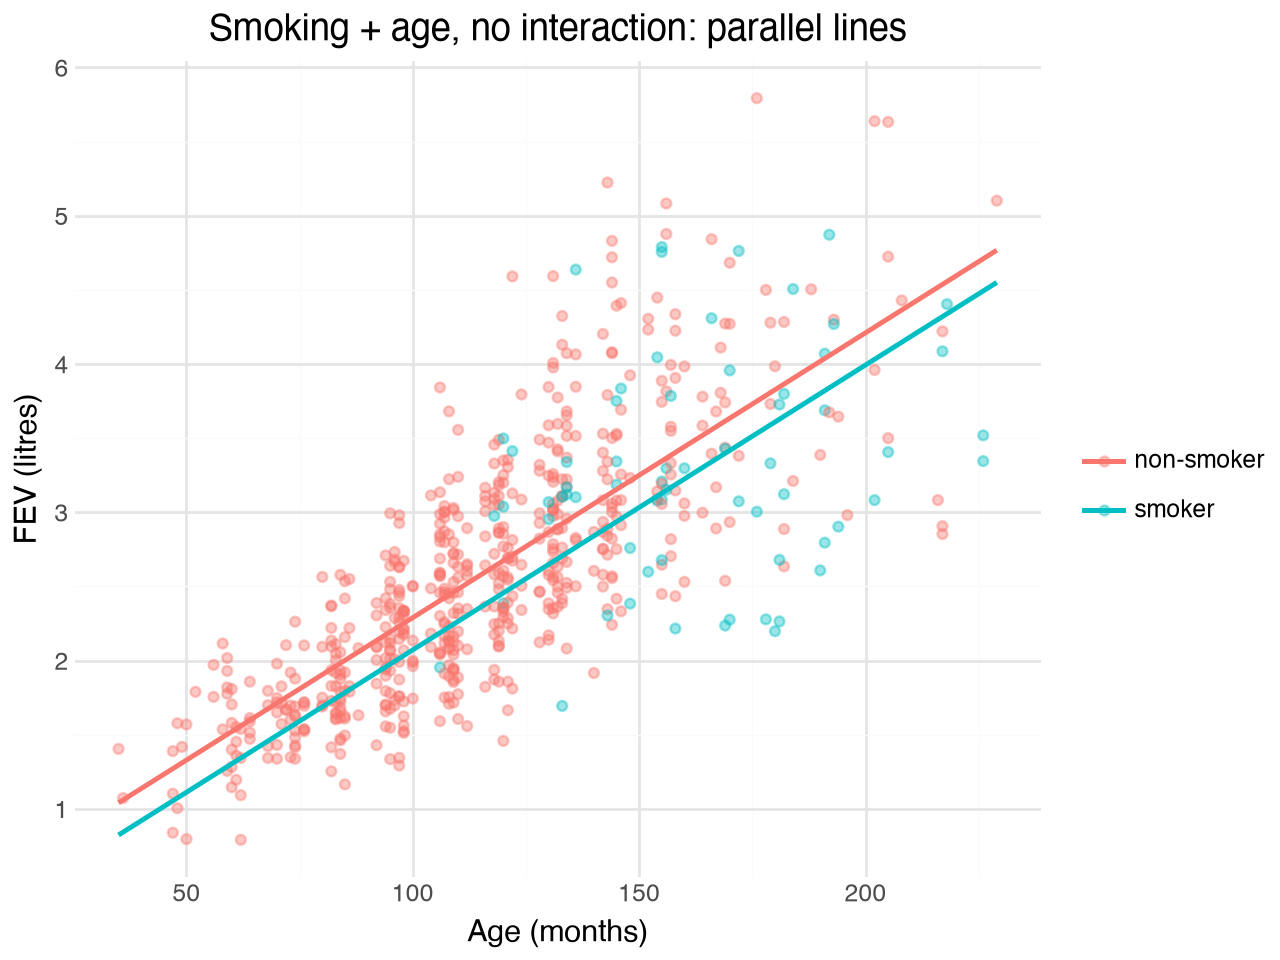

In [19]:
ages = np.linspace(df_fev["age_months"].min(), df_fev["age_months"].max(), 50)
grid_fev = pd.DataFrame({"age_months": np.tile(ages, 2), "smoker": np.repeat([0, 1], 50)})
grid_fev["smoking"] = np.where(grid_fev["smoker"] == 1, "smoker", "non-smoker")
grid_fev["additive"] = smoke_age_model.predict(grid_fev[["smoker", "age_months"]])

(ggplot(df_fev, aes(x="age_months", y="FEV", color="smoking"))
 + geom_point(alpha=0.4)
 + geom_line(grid_fev, aes(y="additive"), size=1)
 + labs(x="Age (months)", y="FEV (litres)", color="", title="Smoking + age, no interaction: parallel lines")
 + theme_minimal())

**What the code does.** `np.tile` repeats the 50 ages twice; `np.repeat([0, 1], 50)` gives 50 zeros then 50
ones, so the grid has one row per (age, group). `geom_line` inherits `x` and `color` from the top-level `aes`
and only overrides `y`. The column names in `aes` must match the renamed columns from FEV-1 (same `smoking`
label so the colours line up with the points).

**Expected output.** Non-smokers (mostly younger) spread across the whole age range; the 65 smokers cluster
at ages ≈ 9–19 years (≈ 105–225 months) at the top right. Two parallel lines, the smoker line ≈ 0.22 L
*below* the non-smoker line at every age. That is why the raw means lied: the smokers' points are high
because they are **old**, not because they smoke.

**Common mistakes.**
- `aes(x="Age (months)")` on the un-renamed column → a parsing error from plotnine; rename or back-tick.
- Building the grid for one group only → one line, and the question of the smoking gap is lost.
- Using `geom_smooth(method="lm")` with `color="smoking"` → plotnine fits a **separate** line per group, which
  is the *interaction* model of FEV-7, not this one. A good thing to point out when it happens.

7\. Fit a linear regression model with predictors smoking status, Age, and their interaction.

### Solution FEV-7 — smoking, age, and their interaction

**Approach.** An interaction is a column you make: `smoker * age_months`. Three columns in `X`.

In [20]:
df_fev["smoker_x_age"] = df_fev["smoker"] * df_fev["age_months"]
X_int = df_fev[["smoker", "age_months", "smoker_x_age"]]

interaction_model = LinearRegression().fit(X_int, df_fev["FEV"])
print("intercept:", round(interaction_model.intercept_, 4))
print(pd.Series(interaction_model.coef_, index=X_int.columns).round(5))
print("R²:", round(interaction_model.score(X_int, df_fev["FEV"]), 3))

intercept: 0.2595
smoker          1.87006
age_months      0.02016
smoker_x_age   -0.01311
dtype: float64
R²: 0.592


**What the code does.** For non-smokers the interaction column is 0, so their line is intercept + age slope.
For smokers it equals age, so their slope is (age slope + interaction) and their intercept is
(intercept + smoker).

**Expected output.** intercept 0.260; smoker +1.870; age 0.0202; smoker × age −0.0131; $R^2$ 0.59.
Read as two lines: non-smokers gain ≈ 0.020 L per month (**0.24 L/year**); smokers gain only 0.0202 − 0.0131
= 0.0071 L per month (**0.08 L/year**). The large positive `smoker` coefficient is the smoker line's intercept
at age 0 — an extrapolation far below the youngest smoker (≈ 9 years), so it is not interpretable on its own;
what matters is that the smoker line is *flatter*.

**Common mistakes.**
- Interpreting `smoker = +1.87` as "smokers have higher FEV" — that is the intercept at age 0, outside the
  smokers' data. With an interaction, the main effect of a dummy only makes sense at `age = 0`.
- Forgetting to include the two main effects alongside the interaction.

8\. Make a scatterplot of FEV versus Age, colored by smoking status, and overlay a graph of the fitted model.

### Solution FEV-8 — the interaction model on the scatterplot

**Approach.** Same grid as FEV-6 plus the interaction column; the two lines now have different slopes.

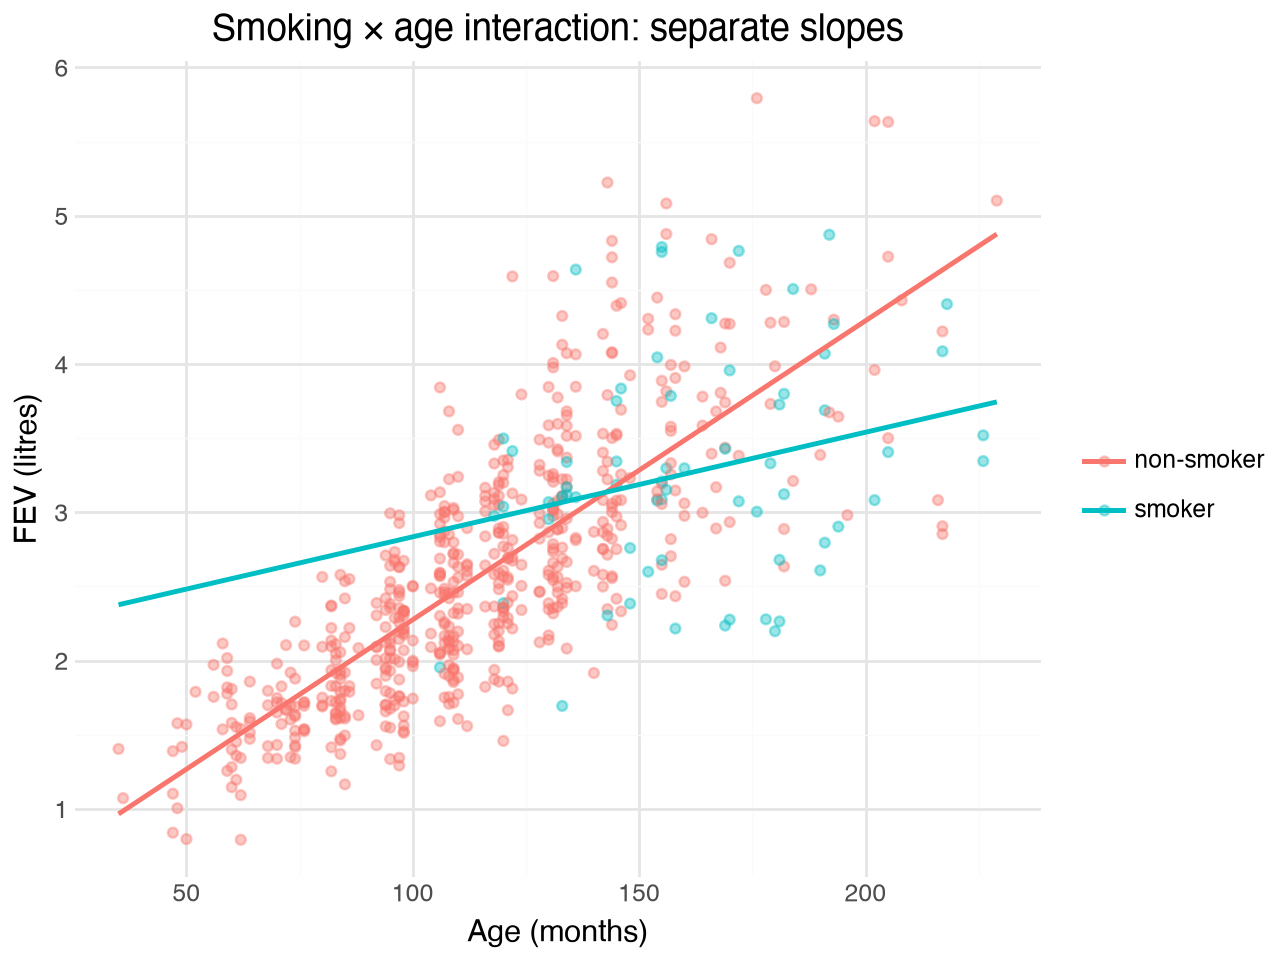

In [21]:
grid_fev["smoker_x_age"] = grid_fev["smoker"] * grid_fev["age_months"]
grid_fev["interaction"] = interaction_model.predict(grid_fev[["smoker", "age_months", "smoker_x_age"]])

(ggplot(df_fev, aes(x="age_months", y="FEV", color="smoking"))
 + geom_point(alpha=0.4)
 + geom_line(grid_fev, aes(y="interaction"), size=1)
 + labs(x="Age (months)", y="FEV (litres)", color="", title="Smoking × age interaction: separate slopes")
 + theme_minimal())

**What the code does.** Identical to FEV-6 with the third column added to the grid and the prediction.

**Expected output.** The non-smoker line rises steeply across the whole range; the smoker line is much
flatter, crossing the non-smoker line at around 11–12 years and sitting below it for older teenagers. Note the
smoker line is drawn all the way down to age 3 because the grid covers the full range — only the part from
≈ 9 years up is supported by smoker data.

**Common mistakes.**
- Reusing `grid_fev` without adding `smoker_x_age` → "expecting 3 features".
- Letting the grid for smokers run below their observed ages and then interpreting the crossing point as a
  finding. (Optional improvement: restrict the smoker grid to `age_months >= 105`.)

9\. Compare the models. Which do you think is "best"? Why? How could you investigate?

**Answer (FEV-9).** On the fitted data, $R^2$ rises 0.06 → 0.58 → 0.59 for smoking only → smoking + age →
+ interaction. The jump from adding age is enormous and real. The jump from adding the interaction is small
(0.576 → 0.592), but the interaction is what makes the smoking story coherent: smokers' lung growth is
*flatter* (0.08 vs 0.24 L/year), which is more plausible than a constant 0.2 L deficit at every age, and it is
the pattern the scatterplot shows. So the interaction model is the best of the three — provisionally.

**How to investigate.** Fitted $R^2$ can only go up when a term is added (Topic 8.2, Checkpoint 2), so it
cannot by itself say whether the interaction *earns* its place. Judge on data the model did not fit: a
train/test split or, better, **cross-validation** — fit each model on part of the 654 children, measure RMSE on
the rest, repeat, average. (For the record, 5-fold CV RMSE here is ≈ 0.84 → 0.57 → 0.56 L: the interaction
helps a little out of sample too.) Beyond that: add **height**, which is in the data and is the most direct
driver of lung volume; check residual plots for curvature in age; and remember that none of this is
causal — it is an observational study, and "flatter growth among smokers" is an association that other
differences between the groups could produce.